<a href="https://colab.research.google.com/github/DEEPIKAGRACE22/PS-7---AI-Assisted-Quality-Inspection-IBM-x-MAH-Quantum-project-/blob/main/ps7_train_and_evaluate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PS-7: AI-Assisted Quality Inspection — Training & Per-Class Evaluation
**Run top to bottom in ONE Colab session (Runtime → GPU). Do not interrupt training.**

Pipeline: rebuild NEU-DET YOLO dataset → train **v1** (50% of train) → evaluate on held-out test →
mine hard images from the unused pool → train **v2** (v1 data + hard images) → compare per class.

Split (seed 42): train 1,260 / val 360 / test 180. Test is never used for training or epoch selection.
Dataset: NEU-DET (Kaggle mirror `kaustubhdikshit/neu-surface-defect-database`) — cite name, link, license in README.

In [1]:
%pip install -q ultralytics kagglehub pandas matplotlib
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - switch runtime to GPU")

GPU: Tesla T4


## 1. Dataset: download, convert VOC→YOLO, split

In [2]:
import random, shutil, xml.etree.ElementTree as ET
from pathlib import Path
import kagglehub

SEED = 42
TEST_PER_CLASS = 30
CLASS_NAMES = ["crazing","inclusion","patches","pitted_surface","rolled-in_scale","scratches"]
CLASS_TO_ID = {n:i for i,n in enumerate(CLASS_NAMES)}
IMG_EXT = {".jpg",".jpeg",".png",".bmp"}
OUT = Path("/content/neu_yolo")

SRC = Path(kagglehub.dataset_download("kaustubhdikshit/neu-surface-defect-database")) / "NEU-DET"
print("Source:", SRC)

def voc_to_yolo(xml_path, img_path):
    root = ET.parse(xml_path).getroot()
    w = int(root.find("size").findtext("width")); h = int(root.find("size").findtext("height"))
    lines = []
    for obj in root.findall("object"):
        name = obj.findtext("name")
        if name not in CLASS_TO_ID: raise ValueError(f"Unknown class {name} in {xml_path.name}")
        b = obj.find("bndbox")
        x1 = max(0, min(float(b.findtext("xmin")), w)); x2 = max(0, min(float(b.findtext("xmax")), w))
        y1 = max(0, min(float(b.findtext("ymin")), h)); y2 = max(0, min(float(b.findtext("ymax")), h))
        if x2 <= x1 or y2 <= y1: raise ValueError(f"Bad box in {xml_path.name}")
        lines.append(f"{CLASS_TO_ID[name]} {(x1+x2)/2/w:.6f} {(y1+y2)/2/h:.6f} {(x2-x1)/w:.6f} {(y2-y1)/h:.6f}")
    if not lines: raise ValueError(f"No objects in {xml_path.name}")
    return "\n".join(lines) + "\n"

xml_by_stem = {}
for p in SRC.rglob("*.xml"):
    assert p.stem not in xml_by_stem, f"Duplicate XML {p.stem}"
    xml_by_stem[p.stem] = p

rng = random.Random(SEED)
splits = {"train": [], "val": [], "test": []}
for cls in CLASS_NAMES:
    tr = sorted(p for p in (SRC/"train"/"images"/cls).iterdir() if p.suffix.lower() in IMG_EXT)
    va = sorted(p for p in (SRC/"validation"/"images"/cls).iterdir() if p.suffix.lower() in IMG_EXT)
    assert len(tr) == 240 and len(va) == 60, (cls, len(tr), len(va))
    rng.shuffle(tr)
    splits["test"] += tr[:TEST_PER_CLASS]
    splits["train"] += tr[TEST_PER_CLASS:]
    splits["val"] += va

if OUT.exists(): shutil.rmtree(OUT)
for split, imgs in splits.items():
    (OUT/"images"/split).mkdir(parents=True); (OUT/"labels"/split).mkdir(parents=True)
    for img in imgs:
        shutil.copy2(img, OUT/"images"/split/img.name)
        (OUT/"labels"/split/f"{img.stem}.txt").write_text(voc_to_yolo(xml_by_stem[img.stem], img))

def write_yaml(path, train_entry):
    txt = (f"path: {OUT}\ntrain: {train_entry}\nval: images/val\ntest: images/test\nnames:\n"
           + "".join(f"  {i}: {n}\n" for i,n in enumerate(CLASS_NAMES)))
    Path(path).write_text(txt)

write_yaml(OUT/"data_full.yaml", "images/train")
for s in splits:
    n = len(list((OUT/"images"/s).glob("*"))); l = len(list((OUT/"labels"/s).glob("*.txt")))
    print(f"{s}: {n} images, {l} labels")
    assert n == l

Using Colab cache for faster access to the 'neu-surface-defect-database' dataset.
Source: /kaggle/input/neu-surface-defect-database/NEU-DET
train: 1260 images, 1260 labels
val: 360 images, 360 labels
test: 180 images, 180 labels


## 2. Build the v1 subset (50% of train, stratified per class)
v1 is the deliberately smaller "before" model. The unused half becomes the **pool** that simulates newly arriving, unlabeled-by-the-model production images.

In [3]:
def cls_of(path): return Path(path).stem.rsplit("_", 1)[0]

train_imgs = sorted((OUT/"images"/"train").glob("*.jpg"))
rng = random.Random(SEED)
v1_imgs, pool_imgs = [], []
for cls in CLASS_NAMES:
    items = [p for p in train_imgs if cls_of(p) == cls]
    rng.shuffle(items)
    k = len(items) // 2
    v1_imgs += items[:k]; pool_imgs += items[k:]

(OUT/"train_v1.txt").write_text("\n".join(str(p) for p in v1_imgs) + "\n")
write_yaml(OUT/"data_v1.yaml", str(OUT/"train_v1.txt"))
print("v1 train images:", len(v1_imgs), "| pool images:", len(pool_imgs))

v1 train images: 630 | pool images: 630


## 3. Training + evaluation helpers

In [4]:
import pandas as pd
from ultralytics import YOLO

RUNS = "/content/ps7_runs"
AUG = dict(hsv_h=0.015, hsv_s=0.3, hsv_v=0.2, degrees=3.0, translate=0.05, scale=0.15, shear=1.0,
           mosaic=0.5, mixup=0.05, close_mosaic=10, fliplr=0.5, flipud=0.0)

def train(run_name, data_yaml, epochs=50, patience=15):
    model = YOLO("yolo11n.pt")
    model.train(data=str(data_yaml), epochs=epochs, imgsz=640, batch=16, device=0,
                seed=SEED, deterministic=True, project=RUNS, name=run_name, exist_ok=True,
                patience=patience, workers=2, plots=True, **AUG)
    best = Path(RUNS)/run_name/"weights"/"best.pt"
    assert best.exists(), "best.pt missing - check training logs"
    return best

def evaluate(weights, tag, split="test"):
    m = YOLO(str(weights)).val(data=str(OUT/"data_full.yaml"), split=split, imgsz=640, batch=16,
                               device=0, plots=True, project=RUNS, name=f"{tag}_{split}", exist_ok=True)
    rows = [dict(model=tag, cls=m.names[c], precision=float(m.box.p[i]), recall=float(m.box.r[i]),
                 mAP50=float(m.box.ap50[i]), mAP50_95=float(m.box.maps[c]))
            for i, c in enumerate(m.box.ap_class_index)]
    rows.append(dict(model=tag, cls="ALL (mean)", precision=float(m.box.mp), recall=float(m.box.mr),
                     mAP50=float(m.box.map50), mAP50_95=float(m.box.map)))
    df = pd.DataFrame(rows)
    df.to_csv(f"/content/metrics_{tag}_{split}.csv", index=False)
    return df

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## 4. Train v1 and evaluate on the held-out test set

In [5]:
BEST_V1 = train("neu_v1_half", OUT/"data_v1.yaml")
print("v1 weights:", BEST_V1)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/neu_yolo/data_v1.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.3, hsv_v=0.2, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.05, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=neu_v1_half, nbs=64, nms=None, opset=None, optimize=False,

In [6]:
m_v1 = evaluate(BEST_V1, "v1")
display(m_v1.round(3))

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 661.4±266.5 MB/s, size: 17.4 KB)
val: Scanning /content/neu_yolo/labels/test... 180 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 180/180 2.0Kit/s 0.1s
val: /content/neu_yolo/images/test/patches_198.jpg: 1 duplicate labels removed
val: New cache created: /content/neu_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 3.5it/s 3.4s
                   all        180        415      0.632      0.648      0.689       0.38
               crazing         30         70      0.461      0.243      0.307      0.111
             inclusion         40        110      0.669      0.682      0.748      0.359
               patches         31         74      0.678      0.716      0.814      0.529
   

,model,cls,precision,recall,mAP50,mAP50_95
0,v1,crazing,0.461,0.243,0.307,0.111
1,v1,inclusion,0.669,0.682,0.748,0.359
2,v1,patches,0.678,0.716,0.814,0.529
3,v1,pitted_surface,0.655,0.861,0.795,0.577
4,v1,rolled-in_scale,0.516,0.604,0.585,0.267
5,v1,scratches,0.814,0.781,0.883,0.436
6,v1,ALL (mean),0.632,0.648,0.689,0.380


## 5. Mine hard images from the pool (simulated review of flagged frames)
Run v1 on the pool. Images where v1 finds **nothing**, or only low-confidence boxes, are the ones a human reviewer would label first.
Their annotations already exist in NEU-DET, so "labeling" = adding them to the training set.

In [7]:
HARD_FRACTION = 0.5   # add the hardest 50% of the pool
v1 = YOLO(str(BEST_V1))
scores = []
for p in pool_imgs:
    r = v1.predict(source=str(p), imgsz=640, conf=0.25, device=0, verbose=False)[0]
    scores.append((float(r.boxes.conf.max()) if len(r.boxes) else 0.0, p))
scores.sort(key=lambda t: t[0])
n_add = int(len(scores) * HARD_FRACTION)
hard_imgs = [p for _, p in scores[:n_add]]

pd.DataFrame([dict(image=p.name, max_conf=s) for s, p in scores]).to_csv("/content/pool_scores_v1.csv", index=False)
print(f"Adding {len(hard_imgs)} hard images; missed entirely: {sum(1 for s,_ in scores if s == 0.0)}")

v2_imgs = v1_imgs + hard_imgs
(OUT/"train_v2.txt").write_text("\n".join(str(p) for p in v2_imgs) + "\n")
write_yaml(OUT/"data_v2.yaml", str(OUT/"train_v2.txt"))
print("v2 train images:", len(v2_imgs))

Adding 315 hard images; missed entirely: 55
v2 train images: 945


## 6. Train v2 and evaluate on the SAME test set

In [8]:
BEST_V2 = train("neu_v2_hard_added", OUT/"data_v2.yaml")
m_v2 = evaluate(BEST_V2, "v2")
display(m_v2.round(3))

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/neu_yolo/data_v2.yaml, degrees=3.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.3, hsv_v=0.2, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.05, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=neu_v2_hard_added, nbs=64, nms=None, opset=None, optimize=

,model,cls,precision,recall,mAP50,mAP50_95
0,v2,crazing,0.605,0.300,0.479,0.182
1,v2,inclusion,0.777,0.745,0.815,0.410
2,v2,patches,0.823,0.784,0.878,0.533
3,v2,pitted_surface,0.791,0.806,0.867,0.627
4,v2,rolled-in_scale,0.709,0.634,0.643,0.319
5,v2,scratches,0.860,0.911,0.930,0.527
6,v2,ALL (mean),0.761,0.697,0.768,0.433


## 7. Before vs after (per class)

,v1_precision,v2_precision,v1_recall,v2_recall,v1_mAP50,v2_mAP50,delta_mAP50,v1_mAP50_95,v2_mAP50_95,delta_mAP50_95
cls,,,,,,,,,,
crazing,0.461,0.605,0.243,0.300,0.307,0.479,0.172,0.111,0.182,0.071
inclusion,0.669,0.777,0.682,0.745,0.748,0.815,0.067,0.359,0.410,0.051
patches,0.678,0.823,0.716,0.784,0.814,0.878,0.064,0.529,0.533,0.005
pitted_surface,0.655,0.791,0.861,0.806,0.795,0.867,0.071,0.577,0.627,0.050
rolled-in_scale,0.516,0.709,0.604,0.634,0.585,0.643,0.057,0.267,0.319,0.052
scratches,0.814,0.860,0.781,0.911,0.883,0.930,0.046,0.436,0.527,0.092
ALL (mean),0.632,0.761,0.648,0.697,0.689,0.768,0.080,0.380,0.433,0.053


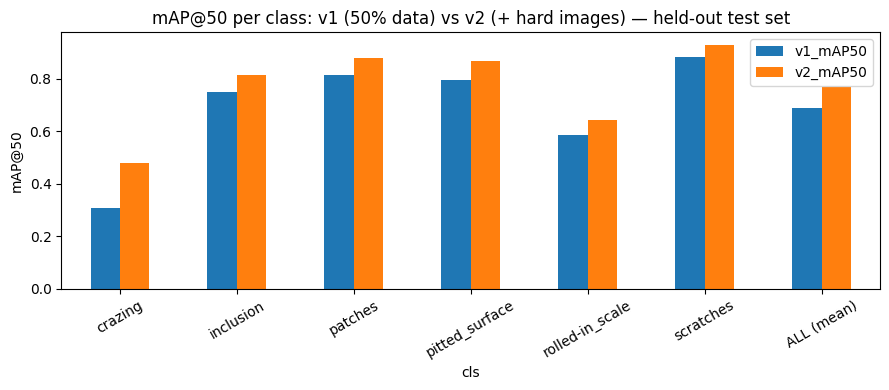

In [9]:
import matplotlib.pyplot as plt
a = m_v1.set_index("cls"); b = m_v2.set_index("cls")
cmp = pd.DataFrame({
    "v1_precision": a.precision, "v2_precision": b.precision,
    "v1_recall": a.recall, "v2_recall": b.recall,
    "v1_mAP50": a.mAP50, "v2_mAP50": b.mAP50, "delta_mAP50": b.mAP50 - a.mAP50,
    "v1_mAP50_95": a.mAP50_95, "v2_mAP50_95": b.mAP50_95, "delta_mAP50_95": b.mAP50_95 - a.mAP50_95,
}).round(3)
cmp.to_csv("/content/before_after_comparison.csv")
display(cmp)

ax = cmp[["v1_mAP50", "v2_mAP50"]].plot.bar(figsize=(9, 4), rot=30)
ax.set_title("mAP@50 per class: v1 (50% data) vs v2 (+ hard images) — held-out test set")
ax.set_ylabel("mAP@50"); plt.tight_layout(); plt.savefig("/content/before_after_map50.png", dpi=150); plt.show()

## 8. Save everything
Download these and keep them: `best_v1.pt`, `best_v2.pt` (v2 is the production model for the streaming pipeline), metrics CSVs, comparison CSV/PNG.
**Honesty note for the report:** report numbers exactly as produced, including classes that got worse. Single-seed runs on 180 test images are noisy, so say so.

In [10]:
import zipfile
shutil.copy2(BEST_V1, "/content/best_v1.pt"); shutil.copy2(BEST_V2, "/content/best_v2.pt")
bundle = "/content/ps7_training_outputs.zip"
with zipfile.ZipFile(bundle, "w") as z:
    for f in ["best_v1.pt", "best_v2.pt", "metrics_v1_test.csv", "metrics_v2_test.csv",
              "before_after_comparison.csv", "before_after_map50.png", "pool_scores_v1.csv"]:
        z.write(f"/content/{f}", f)
    for run in ["v1_test", "v2_test"]:
        for img in (Path(RUNS)/run).glob("*.png"): z.write(img, f"{run}/{img.name}")
try:
    from google.colab import files; files.download(bundle)
except ImportError:
    print("Not in Colab; bundle at", bundle)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>